## Following kernels will load source name text files into a filtered ARCHS4 database

### Function to load sample names from text file

In [1]:
import glob
import sys
import h5py
import archs4py as a4
import re
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
def load_sample_names(txt_file_path):
    """Load sample names from a text file"""
    with open(txt_file_path, 'r') as f:
        sample_names = [line.strip() for line in f if line.strip()]
    return sample_names

In [3]:
%cd /scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/
class_sample_dict = dict()

# loop through all file paths in current directory to find files of interest
for filename in glob.glob("*3.txt"):
    file_path = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/" + filename
    # sample_names are within the text files and are the values of the class_sample_dict
    sample_names = load_sample_names(file_path)
    # class names are within the names of the text files
    class_name = filename.replace("3.txt","")

    class_sample_dict[class_name] = sample_names

/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering


In [4]:
class_sample_dict

{'Kupffer': ['HUMAN HEPATIC MACROPHAGES',
  'SORTED KUPFFER CELLS',
  'LIVER (HEPATOCYTES + KUPFFER CELLS)',
  'HUMAN KUPFFER CELLS'],
 'Langerhans': ['LANGERHANS CELL-DERIVED DENDRITIC CELL',
  'PANCREATIC ISLETS OF LANGERHANS_BLEO',
  'PANCREATIC ISLETS OF LANGERHANS_VEH',
  'MONOCYTE-DERIVED LANGERHANS CELLS',
  'MONOCYTE-DERIVED LANGERHANS CELL',
  'ISLETS OF LANGERHANS'],
 'Macrophage': ['PCA-ASSOCIATED CD14+CD11B+ MACROPHAGES',
  'WT ESC-DERIVED MACROPHAGE',
  'PERIPHERAL BLOOD MONOCYTE-DERIVED MACROPHAGES',
  'PRIMARY MACROPHAGE',
  'PRIMARY HUMAN MONOCYTE-DERIVED MACROPHAGES, ADMAF, IFN-Î³',
  'MACROPHAGE WITH CONTROL LNA 24H_REP#2',
  'MACROPHAGE_6D_MEDIA_MTB_4H',
  'PRIMARY HUMAN MACROPHAGE CELLS',
  'H1 ESC-DERIVED M1 MACROPHAGES',
  'MACROPHAGES(BC9)',
  'HUMAN MONOCYTE-DERIVED MACROPHAGE',
  'ACTIVATED MONOCYTE-DERIVED MACROPHAGES',
  'PERIPHERAL_BLOOD_MACROPHAGE-M0_SICTRL',
  'IPSC-DERIVED M0 MACROPHAGE',
  'HU-CB-MACROPHAGE-RNA, WT-CB',
  'BONE MARROW DERIVED MACROPHAGE'

### Filters human_tpm_v2.2_NOSC.h5 into a filtered file containing source names in class_sample_dict

In [5]:
transcript_file_path = "/scratch/by2372/pipeline/ARCHS4_Macrophages/human_tpm_v2.2_NOSC.h5"
a4.ls(transcript_file_path)

data                      
│ expression            float32 | (271742, 661840)
meta                      
│ samples                   
│   characteristics_ch1   str    | (661840,)
│   source_name_ch1       str    | (661840,)
│ transcripts               
│   ensembl_id            str    | (271742,)
│   symbol                str    | (271742,)


In [ ]:

with h5py.File(transcript_file_path, "r") as fin, h5py.File('filtered_ARCHS4_7_class.h5', 'w') as fout:

    # copy the ensembl_ids and gene symbols to the new h5 file
    fin.copy("meta/transcripts/ensembl_id", fout)
    fin.copy("meta/transcripts/symbol", fout) 
    
    # Navigate to the metadata group for source names
    source_name_ds = fin['meta/samples/source_name_ch1']

    # Read all names and decode bytes to strings
    source_names = source_name_ds[:]
    if isinstance(source_names[0], bytes):
        source_names = [s.decode('utf-8') for s in source_names]

    # Get dataset info
    expr_dataset = fin['data/expression']
    n_genes, n_samples = expr_dataset.shape

    filtered_dataset = fout.create_dataset(
        "data/filtered_expression",
        (n_genes, 0),                    # start with 0 samples
        maxshape=(n_genes, None),        # allow dynamic extension
        dtype=expr_dataset.dtype,
        chunks=True
    )
    
    class_name_dataset = fout.create_dataset(
        "class_name",
        (0,),                            # start empty
        maxshape=(None,),                # allow appending
        dtype=source_name_ds.dtype,
        chunks=True
    )

    current_pos = 0

    for key, value in class_sample_dict.items():

        print("Matching indices for " + str(key))

        
        matched_indices = []
        class_names = []
        
        for filt_name in set(value): 
            matched_indices.extend([
                i for i, n in enumerate(source_names)
                if n.lower() == filt_name.lower()
            ])

        matched_indices.sort()
        n_new = len(matched_indices)
        print(str(n_new))
        cur_class_names = [key] * n_new
        class_names.append(cur_class_names)

        filtered_dataset.resize((n_genes, current_pos + n_new))
        class_name_dataset.resize((current_pos + n_new,))
        
        # Process in chunks of genes instead of loading all at once
        chunk_size = 1000  # Adjust based on your memory
        iteration = 0
        for start_gene in range(0, n_genes, chunk_size):
            end_gene = min(start_gene + chunk_size, n_genes)
            
            # Read chunk of data for matched samples only
            chunk_data = expr_dataset[start_gene:end_gene, matched_indices]
            
            # Write to output
            filtered_dataset[start_gene:end_gene, current_pos:current_pos + n_new] = chunk_data
            iteration = iteration + 1
            print("Iteration " + str(iteration)+ " is done.")
            sys.stdout.flush()


        class_name_dataset[current_pos:current_pos + n_new] = class_names
        
        current_pos += n_new

Matching indices for Kupffer
35
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
Iteration 9 is done.
Iteration 10 is done.
Iteration 11 is done.
Iteration 12 is done.
Iteration 13 is done.
Iteration 14 is done.
Iteration 15 is done.
Iteration 16 is done.
Iteration 17 is done.
Iteration 18 is done.
Iteration 19 is done.
Iteration 20 is done.
Iteration 21 is done.
Iteration 22 is done.
Iteration 23 is done.
Iteration 24 is done.
Iteration 25 is done.
Iteration 26 is done.
Iteration 27 is done.
Iteration 28 is done.
Iteration 29 is done.
Iteration 30 is done.
Iteration 31 is done.
Iteration 32 is done.
Iteration 33 is done.
Iteration 34 is done.
Iteration 35 is done.
Iteration 36 is done.
Iteration 37 is done.
Iteration 38 is done.
Iteration 39 is done.
Iteration 40 is done.
Iteration 41 is done.
Iteration 42 is done.
Iteration 43 is done.
Iteration 44 is done.
Iteration

# Following code will filter the database for TF genes only

In [7]:
filtered_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_ARCHS4_7_class.h5"
tf_names = load_sample_names("/scratch/by2372/pipeline/tf_names.txt")
a4.ls(filtered_file)

class_name            str    | (10775,)
data                      
│ filtered_expression   float32 | (271742, 10775)
ensembl_id            str    | (271742,)
symbol                str    | (271742,)


In [8]:
# Read in the filtered ARCHS4 h5 and write out to a new h5
with h5py.File(filtered_file, "r") as fin, h5py.File('filtered_ARCHS4_TFs_7_class.h5', 'w') as fout:

    # Copy the class names into the new h5
    fin.copy("class_name", fout) 
    # Read in the gene symbol and ensembl IDs from the input h5 file
    symbols = fin["symbol"]
    ensembl_id = fin["ensembl_id"]

    # unpack the gene symbol names and decode bytes to strings
    symbols_unpack = symbols[:]
    if isinstance(symbols_unpack[0], bytes):
        symbols_unpack = [s.decode('utf-8') for s in symbols_unpack]

    # unapck the ensembl IDs and decode bytes to strings
    ensembl_unpack = ensembl_id[:]
    if isinstance(ensembl_unpack[0], bytes):
        ensembl_unpack = [s.decode('utf-8') for s in ensembl_unpack]

    # initialize the total number of genes in the input h5, an empty matched index list and the processing chunk size
    n_genes = len(symbols)
    tf_matched_indices = []
    chunk_size = 1000

    # iterate through indices of all genes in the input h5 by chunking through them
    for start_gene in range(0, n_genes, chunk_size):
        end_gene = min(start_gene + chunk_size, n_genes)
        chunk_symbols = symbols_unpack[start_gene:end_gene]

        # find the indices that match the list of known human TFs
        for i, sym in enumerate(chunk_symbols):
            if sym in tf_names:
                idx = start_gene + i
                tf_matched_indices.append(idx)

    tf_matched_indices.sort()
    print("Matched indices for TFs have been found")
    
    # Create output dataset for gene symbol in the output h5
    new_sym_dataset = fout.create_dataset(
        "symbol", 
        (len(tf_matched_indices), ),
        dtype=symbols.dtype,
        chunks=True
    )

    # Create output dataset for ensembl ID in the output h5
    new_ensembl_dataset = fout.create_dataset(
        "ensembl_id", 
        (len(tf_matched_indices), ),
        dtype=ensembl_id.dtype,
        chunks=True
    )

    # convert symbols and ensembl IDs to np arrays
    symbols_arr = np.array(symbols_unpack)
    ensembl_arr = np.array(ensembl_unpack)

    # have only the matched indices be the new symbols and ensembl ID datasets
    new_sym_dataset[...] = symbols_arr[tf_matched_indices]
    new_ensembl_dataset[...] = ensembl_arr[tf_matched_indices]

    # Get dataset info
    expr_dataset = fin['data/filtered_expression']
    n_genes, n_samples = expr_dataset.shape

    # Create output dataset
    filtered_dataset = fout.create_dataset(
        "data/filtered_expression", 
        (len(tf_matched_indices), n_samples),
        dtype=expr_dataset.dtype,
        chunks=True
    )

    # do a chunking approach to chunk through the number of samples in 1000 chunks 
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)
        data_chunk = expr_dataset[tf_matched_indices, start_sample:end_sample]
        filtered_dataset[:, start_sample:end_sample] = data_chunk
        print("Iteration " + str(iteration)+ " is done.")
        iteration += 1


Matched indices for TFs have been found
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
Iteration 9 is done.
Iteration 10 is done.


In [9]:
filtered_TFs_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_ARCHS4_TFs_7_class.h5"
a4.ls(filtered_TFs_file)

class_name            str    | (10775,)
data                      
│ filtered_expression   float32 | (13146, 10775)
ensembl_id            str    | (13146,)
symbol                str    | (13146,)


# The code below will create training and testing datasets

In [10]:
def chunk_samples(chunk_size, n_samples, n_genes, output, input):
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)

        for start_gene in range(0, n_genes, chunk_size):
            end_gene = min(start_gene + chunk_size, n_genes)

            # Read a chunk of the input matrix
            data_chunk = input[start_sample:end_sample, start_gene:end_gene]

            # Write the chunk to the output dataset
            output[start_sample:end_sample, start_gene:end_gene] = data_chunk

        print("Iteration " + str(iteration) + " (samples " + str(start_sample) + "-" + str(end_sample) + ") is done.")
        iteration += 1

In [11]:
def chunk_class(chunk_size,n_samples,output,input):
    iteration = 0
    for start_sample in range(0, n_samples, chunk_size):
        end_sample = min(start_sample + chunk_size, n_samples)
        data_chunk = input[start_sample:end_sample]
        output[start_sample:end_sample] = data_chunk
        print("Iteration " + str(iteration)+ " is done.")
        iteration += 1

In [14]:
# Make Rows be the samples and the columns be the transcripts
# make it into a data frame and export as H5
with h5py.File(filtered_TFs_file, "r") as fin, h5py.File('filtered_training_7_class.h5', 'w') as ftrain, h5py.File('filtered_testing_7_class.h5', 'w') as ftest:

    # Navigate to the metadata group for class names, gene symbols, and ensembl ID
    class_name_ds = fin['class_name']
    ensembl_id = fin["ensembl_id"]
    symbols = fin["symbol"]

    # Read all names and decode bytes to strings
    symbols_unpack = symbols[:]
    if isinstance(symbols_unpack[0], bytes):
        symbols_unpack = [s.decode('utf-8') for s in symbols_unpack]

    # Read all names and decode bytes to strings
    class_names = class_name_ds[:]
    if isinstance(class_names[0], bytes):
        class_names = [s.decode('utf-8') for s in class_names]

    ensembl_unpack = ensembl_id[:]
    if isinstance(ensembl_unpack[0], bytes):
        ensembl_unpack = [s.decode('utf-8') for s in ensembl_unpack]

    # Navigate to the metadata group for the expression data
    expression = fin["data/filtered_expression"]

    # Transpose expression data so that rows are samples and columns are transcripts
    expression_data = expression[:, :] 
    expression_data = expression_data.T
    print("Expression data has been transposed\n")

    # Make the transcript ID be the symbol _ ensembl ID
    transcript_ID = []
    for idx, sym in enumerate(symbols_unpack):
        ID = sym + "_" + ensembl_unpack[idx]
        transcript_ID.append(ID)

    filtered_df = pd.DataFrame(expression_data,index = class_names, columns = transcript_ID)
    filtered_df['cell_identity'] = class_names

    # Count occurrences of each cell_identity
    cell_identity_counts = filtered_df['cell_identity'].value_counts()
    print(cell_identity_counts)

    # Create a boolean mask to filter rows with cell_identity occurring more than once
    mask = filtered_df['cell_identity'].isin(cell_identity_counts[cell_identity_counts > 1].index)

    # Filter the DataFrame using the mask
    filtered_df = filtered_df[mask]

    # Seperate the ensmbl ids from the cell_identity column
    TFs = filtered_df.columns.drop(['cell_identity'])

    # Set predictors and predicted
    X = np.array(filtered_df[TFs])
    y = np.array(filtered_df['cell_identity'])

    # Train - test split with stratification and shuffling
    ### THIS LOADS IN THE WHOLE H5 FILE TO SPLIT
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=5, stratify=y,shuffle = True)

    # Create output dataset
    X_train_out = ftrain.create_dataset(
        "expression", 
        (X_train.shape[0], X_train.shape[1]),
        dtype=expression.dtype,
        chunks=True
    )
    print("Starting X Train output into H5")
    chunk_samples(1000,X_train.shape[0],X_train.shape[1],X_train_out,X_train)
    print("X Train output successfully")

    y_train_out = ftrain.create_dataset(
        "label",
        len(y_train),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting y train output into H5")
    chunk_class(1000,len(y_train),y_train_out,y_train)
    print("y Train output successfully")

    TF_ID_out = ftrain.create_dataset(
        "TF_ID",
        len(transcript_ID),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting TF IDs output into training H5")
    chunk_class(1000,len(transcript_ID),TF_ID_out,transcript_ID)
    print("TF ID output successfully")
    
    ###export X_test, y_test with Transcript_ID or TFs to an h5
    
    X_test_out = ftest.create_dataset(
        "expression", 
        (X_test.shape[0], X_test.shape[1]),
        dtype=expression.dtype,
        chunks=True
    )
    print("Starting X Test output into H5")
    chunk_samples(1000,X_test.shape[0],X_test.shape[1],X_test_out,X_test)
    print("X test output successfully")

    y_test_out = ftest.create_dataset(
        "label",
        len(y_test),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting y test output into H5")
    chunk_class(1000,len(y_test),y_test_out,y_test)
    print("y test output successfully")

    TF_ID_out = ftest.create_dataset(
        "TF_ID",
        len(transcript_ID),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks = True
    )
    print("Starting TF IDs output into testing H5")
    chunk_class(1000,len(transcript_ID),TF_ID_out,transcript_ID)
    print("TF ID output successfully")



Expression data has been transposed

cell_identity
Monocyte      5497
Macrophage    4183
Microglia      672
alveolar       195
Langerhans     148
Osteoclast      45
Kupffer         35
Name: count, dtype: int64
Starting X Train output into H5
Iteration 0 (samples 0-1000) is done.
Iteration 1 (samples 1000-2000) is done.
Iteration 2 (samples 2000-3000) is done.
Iteration 3 (samples 3000-4000) is done.
Iteration 4 (samples 4000-5000) is done.
Iteration 5 (samples 5000-6000) is done.
Iteration 6 (samples 6000-7000) is done.
Iteration 7 (samples 7000-8000) is done.
Iteration 8 (samples 8000-8081) is done.
X Train output successfully
Starting y train output into H5
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 is done.
Iteration 4 is done.
Iteration 5 is done.
Iteration 6 is done.
Iteration 7 is done.
Iteration 8 is done.
y Train output successfully
Starting TF IDs output into training H5
Iteration 0 is done.
Iteration 1 is done.
Iteration 2 is done.
Iteration 3 

In [15]:
train_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_training_7_class.h5"
#redownload the most recent transcript file
a4.ls(train_file)

TF_ID                 str    | (13146,)
expression            float32 | (8081, 13146)
label                 str    | (8081,)


In [16]:
test_file = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_testing_7_class.h5"
#redownload the most recent transcript file
a4.ls(test_file)

TF_ID                 str    | (13146,)
expression            float32 | (2694, 13146)
label                 str    | (2694,)


In [17]:
pd.Series(y_train).value_counts()

Monocyte      4123
Macrophage    3137
Microglia      504
alveolar       146
Langerhans     111
Osteoclast      34
Kupffer         26
Name: count, dtype: int64

In [18]:
pd.Series(y_test).value_counts()

Monocyte      1374
Macrophage    1046
Microglia      168
alveolar        49
Langerhans      37
Osteoclast      11
Kupffer          9
Name: count, dtype: int64

### Load in training and testing data here 

In [11]:
f_train = h5py.File("/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_training_7_class.h5", 'r')
expression_train = f_train['expression'][...]
label_train = f_train['label'][...]
f_train.close()
f_test = h5py.File("/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_testing_7_class.h5", 'r')
expression_test = f_test['expression'][...]
label_test = f_test['label'][...]

TFs = f_test['TF_ID'][...]

expression_train = np.log2(expression_train + 1)
expression_test = np.log2(expression_test + 1)

# Read all names and decode bytes to strings
if isinstance(label_train[0], bytes):
    label_train = [s.decode('utf-8') for s in label_train]

# Read all names and decode bytes to strings
if isinstance(label_test[0], bytes):
    label_test = [s.decode('utf-8') for s in label_test]

# Read all names and decode bytes to strings
if isinstance(TFs[0], bytes):
    TFs = [s.decode('utf-8') for s in TFs]

f_test.close()

In [3]:
expression_train.shape

(8081, 13146)

### Random Oversampler on Training Data

In [4]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

ros = RandomOverSampler(random_state=42)
expression_ros, label_ros = ros.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_ros))

Original class distribution: Counter({'Monocyte': 4123, 'Macrophage': 3137, 'Microglia': 504, 'alveolar': 146, 'Langerhans': 111, 'Osteoclast': 34, 'Kupffer': 26})
Resampled class distribution: Counter({'Monocyte': 4123, 'Microglia': 4123, 'Macrophage': 4123, 'Langerhans': 4123, 'alveolar': 4123, 'Osteoclast': 4123, 'Kupffer': 4123})


### SMOTE on Training Data

In [5]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=0,k_neighbors = 1)
expression_SMOTE, label_SMOTE = smote.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_SMOTE))

Original class distribution: Counter({'Monocyte': 4123, 'Macrophage': 3137, 'Microglia': 504, 'alveolar': 146, 'Langerhans': 111, 'Osteoclast': 34, 'Kupffer': 26})
Resampled class distribution: Counter({'Monocyte': 4123, 'Microglia': 4123, 'Macrophage': 4123, 'Langerhans': 4123, 'alveolar': 4123, 'Osteoclast': 4123, 'Kupffer': 4123})


### BLSMOTE on Training Data

In [6]:
from imblearn.over_sampling import BorderlineSMOTE
from collections import Counter

BLsmote = BorderlineSMOTE(random_state=1,k_neighbors = 1)
expression_BLSMOTE, label_BLSMOTE = BLsmote.fit_resample(expression_train,label_train)

print("Original class distribution:", Counter(label_train))
print("Resampled class distribution:", Counter(label_BLSMOTE))

Original class distribution: Counter({'Monocyte': 4123, 'Macrophage': 3137, 'Microglia': 504, 'alveolar': 146, 'Langerhans': 111, 'Osteoclast': 34, 'Kupffer': 26})
Resampled class distribution: Counter({'Monocyte': 4123, 'Microglia': 4123, 'Macrophage': 4123, 'Langerhans': 4123, 'alveolar': 4123, 'Osteoclast': 4123, 'Kupffer': 4123})


# Below is the code for neural network training

In [2]:
import random
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from tensorflow import keras
import tensorflow as tef
from keras import optimizers
from keras import losses
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize, LabelEncoder
from sklearn.metrics import (f1_score, auc, roc_curve, roc_auc_score)
from tensorflow.keras.models import load_model

2026-10-27 14:37:48.047377: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-27 14:37:52.254091: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-27 14:38:02.633451: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Perform PCA analysis on the Training Data set and Generate PCA Plot

In [8]:
# Make normalized data into a data frame
express_train_df = pd.DataFrame(expression_train, columns = TFs)
PCA_train = PCA(n_components = 2)
PC_expression_train = PCA_train.fit_transform(express_train_df)

PC_expression_train_df = pd.DataFrame(data = PC_expression_train, columns = ['PC1','PC2'])

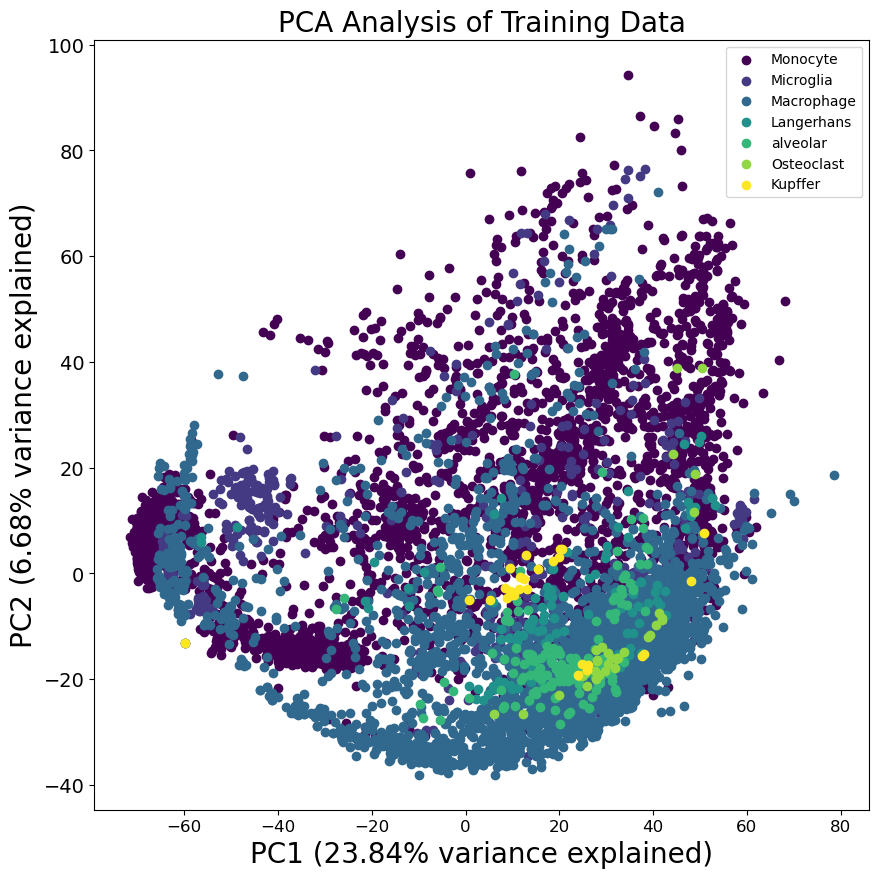

In [9]:
pc1_var = PCA_train.explained_variance_ratio_[0]*100
pc2_var = PCA_train.explained_variance_ratio_[1]*100

plt.figure(figsize=(10,10))
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 14)
plt.xlabel(f'PC1 ({pc1_var:.2f}% variance explained)', fontsize = 20)
plt.ylabel(f'PC2 ({pc2_var:.2f}% variance explained)', fontsize = 20)
plt.title('PCA Analysis of Training Data', fontsize = 20)

label_train_df = pd.DataFrame(data=label_train, columns=['labels'])
unique_labels = label_train_df['labels'].unique()
colors = plt.colormaps['viridis'].resampled(len(unique_labels))

for i, s_type in enumerate(unique_labels):
    indices = label_train_df['labels'] == s_type
    plt.scatter(
        PC_expression_train_df.loc[indices, 'PC1'],
        PC_expression_train_df.loc[indices, 'PC2'],
        color=colors(i),
        label=s_type)

plt.legend()
plt.show()

### Below is the training function for a keras NN model

In [8]:
def NN_training(X_train,y_train,X_test,y_test,TFS,name):

    keras.utils.set_random_seed(10)   
    
    num_unique_y = len(set(y_train))

    le = LabelEncoder()
    
    # Fit on training labels (strings) and transform them to integers
    label_train_int = le.fit_transform(y_train)
    
    # Use the same encoder to transform test labels
    label_test_int = le.transform(y_test)
    
    # Best model in magnussen paper was 2 layers of 250 nodes
    model = keras.Sequential([
        keras.layers.Input(shape=(len(TFs),)),  # there are 13146 TFs
        keras.layers.Dense(250, activation='elu'),
        keras.layers.Dense(250, activation='elu'),
        keras.layers.Dense(num_unique_y, activation='softmax')  # For multiclass classification
    ])

    callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience = 3)
    
    adam = optimizers.Adam(
        learning_rate=0.001,
        beta_1=0.9,
        beta_2=0.999,
        weight_decay=0.01  # replaces old `decay`
    )
    model.compile(loss='sparse_categorical_crossentropy',optimizer=adam,metrics=['accuracy'], )
    history = model.fit(X_train, label_train_int, batch_size=50, epochs=100, verbose=1, validation_split = 0.1, callbacks = [callback])

    model.save("/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/" + name + "_trained_NN.keras")

    np.save("/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/" + name + "_class_names.npy", le.classes_)

    loss, accuracy = model.evaluate(X_test, label_test_int, verbose=1)

    ### Plot the training epochs ###
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].plot(history.history['loss'], label='Training Loss')
    axes[0].plot(history.history['val_loss'], label='Validation Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{name}: Training and Validation Loss')
    axes[0].legend()
    
    axes[1].plot(history.history['accuracy'], label='Training Accuracy')
    axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{name}: Training and Validation Accuracy')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()
    ######

    # Predictions on test set
    y_prob = model.predict(X_test)
    y_pred = np.argmax(y_prob, axis=1)

    # Calculate F1 Metrics
    f1_macro = f1_score(label_test_int, y_pred, average='macro')
    f1_weighted = f1_score(label_test_int, y_pred, average='weighted')
    f1_micro = f1_score(label_test_int,y_pred,average = 'micro')

     # binarize the classes
    cell_classes = np.unique(np.concatenate((label_train_int, label_test_int)))
    y_test_bin = label_binarize(label_test_int, classes=cell_classes)

    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    roc_auc_labeled = dict()

    # One vs. rest AUC calculation for multiclass data
    for i in range(len(cell_classes)):
        cur_class = cell_classes[i]
        fpr[cur_class], tpr[cur_class], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        roc_auc[cur_class] = auc(fpr[cur_class], tpr[cur_class])
        # Inverse transform the label encoder to get the class label once again
        class_label = le.inverse_transform([cur_class])[0]
        roc_auc_labeled[class_label] = roc_auc[cur_class]
        print(f"AUC for class {cur_class}: {roc_auc[cur_class]:.2f}")

    # compute micro-average ROC curve and ROC area
    fpr["micro"], tpr["micro"],_=roc_curve(y_test_bin.ravel(),y_prob.ravel())
    roc_auc_labeled["micro"] = auc(fpr["micro"],tpr["micro"])   

    return {
    "f1_macro": f1_macro,
    "f1_weighted": f1_weighted,
    "f1_micro": f1_micro,
    "roc_auc_micro": roc_auc_labeled["micro"],
    "roc_auc_per_class": roc_auc_labeled,
    "loss" : loss,
    "accuracy" : accuracy
    }

### Below is the model architecutre for Pytorch NN

In [9]:
# nn.Module provides base class Pytorch model. Includes methods that do not need to be defined manually.
class NNClassifier(nn.Module):
    # Defines the model's layers
    def __init__(self, input_dim, num_classes):
        super().__init__()
        # nn.Sequential connections layers in order as shown below
        self.network = nn.Sequential(
            nn.Linear(input_dim,250), # input layer with number of TFs into 250 nodes
            nn.ELU(), # ELU activation function
            nn.Linear(250,250), # previous layer's 250 nodes transforms to another 250 nodes
            nn.ELU(),
            nn.Linear(250, num_classes) # output provides 1 raw score/logit for each class
        )

    # Defines how data passes through the network
    # calling "model(X_batch)" invokes "forward" and produces output logits
    def forward(self, x):
        return self.network(x)

In [10]:
def pytorch_NN_training(X_train,y_train,X_test,y_test,TFS,name):

    # Sets random seeds for reproducibility in repeated runs
    random.seed(10)
    np.random.seed(10)
    torch.manual_seed(10)

    # Sets the seed for GPUs manually
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(10)

    # Has torch access GPU if one is available
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # Encode the training data labels to integer values and encode test data with the same labels
    le = LabelEncoder()
    label_train_int = le.fit_transform(y_train)
    label_test_int = le.transform(y_test)

    num_unique_y = len(le.classes_) #number of classes in data
    input_dim = len(TFS) # number of TFs in data

    # convert the data into tensors for pytorch NN training
    X_train = torch.as_tensor(np.asarray(X_train), dtype=torch.float32)
    X_test = torch.as_tensor(np.asarray(X_test), dtype=torch.float32)
    y_train_tensor = torch.as_tensor(label_train_int, dtype=torch.long)
    y_test_tensor = torch.as_tensor(label_test_int, dtype=torch.long)

    ### Create a random split of the training and validation data
    n_samples = len(X_train)
    n_val = max(1, int(0.1 * n_samples))

    generator = torch.Generator().manual_seed(10)
    permutation = torch.randperm(n_samples, generator=generator)

    val_idx = permutation[:n_val]
    train_idx = permutation[n_val:]

    train_dataset = TensorDataset(X_train[train_idx],y_train_tensor[train_idx])
    val_dataset = TensorDataset(X_train[val_idx],y_train_tensor[val_idx])

    #DataLoader provides batches to training loop
    train_loader = DataLoader(train_dataset, batch_size=50, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=50, shuffle=False)

    # Create instance of the custom pytorch model
    model = NNClassifier(input_dim=input_dim, num_classes = num_unique_y).to(device)

    # CrossEntropyLoss combines log-softmax and NLL loss
    criterion = nn.CrossEntropyLoss()

    #AdamW optimizer adjusts model weights to reduce loss
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001,
        betas=(0.9,0.999),
        weight_decay=0.01
    )

    patience = 3 # stop training is val loss doesn't approve for 3 epochs
    best_val_loss = float('inf') # any improvement of val loss is initially the best
    epochs_without_improvement = 0
    best_state = None

    history = {"train_loss": [], "val_loss": []}

    for epoch in range(100): # 100 epochs of training

        ## Start training of the model
        model.train()
        train_loss_sum = 0.0
        train_count = 0

        for X_batch, y_batch in train_loader:
            # one batch of data moves to the cuda or cpu device each iteration
            X_batch = X_batch.to(device) # shape:(50,13146)
            y_batch = y_batch.to(device) # shape: (50)

            # Step 1 in NN training:
            optimizer.zero_grad() #clears gradients from previous training batch
            # Step 2 in NN training:
            logits = model(X_batch) # calls forward pass for model to get logits
            loss = criterion(logits, y_batch) # compares logits with the correct y labels
            # Step 3 in NN training:
            loss.backward() # backpropagation of weights; estimates loss change when weights are changed
            # Step 4 in NN training:
            optimizer.step() # optimizer updates the weights
            # Calculate the training data set loss
            batch_size = len(y_batch)
            train_loss_sum += loss.item() * batch_size # have to "undo" the average since loss.item returns the averaged loss
            train_count += batch_size 

        train_loss = train_loss_sum / train_count # sample-weighted average loss for epoch

        ## Start Validation of the model
        model.eval()
        val_loss_sum = 0.0
        val_count = 0

        with torch.no_grad(): # no_grad() since validation does not update weights
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                # Call forward pass of model
                logits = model(X_batch)
                loss = criterion(logits, y_batch)
                # calculates validation set loss
                batch_size = len(y_batch)
                val_loss_sum += loss.item() * batch_size
                val_count += batch_size

        val_loss = val_loss_sum / val_count

        print(f"Epoch {epoch+1}/100 - " f"Train Loss: {train_loss:.4f} - " f"Val Loss: {val_loss:.4f} - ")

        # Save best model parameters and invoke early stopping mechanism
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break 

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

    # Restore the weights from the best validation epoch
    model.load_state_dict(best_state)
    model.eval()


    # Save the model and class names
    save_dir = "/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN"
    os.makedirs(save_dir, exist_ok = True)

    torch.save(model.state_dict, os.path.join(save_dir, name+"_trained_pytorch.pt"))

    np.save(os.path.join(save_dir, name+"_class_names_pytorch.npy"),le.classes_)

    ### Plot the training epochs
    plt.figure(figsize=(14,5))
    plt.plot(history["train_loss"],label = "Training Loss")
    plt.plot(history["val_loss"], label = "Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{name}: Training and Validation Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

    ## Test-set evaluation
    test_dataset = TensorDataset(X_test,y_test_tensor)
    test_loader = DataLoader(test_dataset, batch_size=50, shuffle=False)

    test_loss_sum = 0.0
    all_probs = []
    all_preds = []

    with torch.no_grad(): 
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            probs = torch.softmax(logits, dim=1) # converts logits to probs
            preds = torch.argmax(logits, dim=1) # finds highest prob

            test_loss_sum =+ loss.item() * len(y_batch)
            all_probs.append(probs.cpu().numpy())
            all_preds.append(preds.cpu().numpy())

    loss = test_loss_sum / len(test_dataset)
    y_prob = np.concatenate(all_probs, axis=0)
    y_pred = np.concatenate(all_preds, axis=0)

    accuracy = np.mean(y_pred == label_test_int)

    ### Calculate F1 metrics 
    f1_macro = f1_score(label_test_int, y_pred, average="macro")
    f1_weighted = f1_score(label_test_int, y_pred, average="weighted")
    f1_micro = f1_score(label_test_int, y_pred, average="micro")

    # One-vs_rest ROC_AUC
    cell_classes = np.arange(num_unique_y)  # array of evenly space values from 0 to num_unique_y - 1
    y_test_bin = label_binarize(label_test_int, classes=cell_classes) # binarized matrix for each class

    # sklearn returns only one column for binary classfication
    if num_unique_y == 2:
        y_test_bin = np.column_stack([1 - y_test_bin[:,0],y_test_bin[:,0]])

    roc_auc_labeled = {}
    fpr = {}
    tpr = {}

    for i, class_label in enumerate(le.classes_):
        # AUC is undefined if test set has only one outcome for one-vs-rest
        if len(np.unique(y_test_bin[:,i])) < 2:
            roc_auc_labeled[class_label] = float("nan")
            print(f"AUC for {class_label}: undefined")
            continue
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:,i],y_prob[:,i])
        roc_auc_labeled[class_label] = auc(fpr[i],tpr[i])

        print(
            f"AUC for {class_label}: "
            f"{roc_auc_labeled[class_label]:.2f}"
        )

    # Micro-averaged AUC
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(),y_prob.ravel())
    roc_auc_labeled["micro"] = auc(fpr["micro"], tpr["micro"])

    return {
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
        "f1_micro": f1_micro,
        "roc_auc_micro": roc_auc_labeled["micro"],
        "roc_auc_per_class": roc_auc_labeled,
        "loss": loss,
        "accuracy": accuracy
    }

I0000 00:00:1793125924.671929 4044596 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 43516 MB memory:  -> device: 0, name: NVIDIA L40S, pci bus id: 0000:c2:00.0, compute capability: 8.9


Epoch 1/100


2026-10-27 14:32:08.830333: I external/local_xla/xla/service/service.cc:163] XLA service 0x1462e001bb40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-27 14:32:08.830358: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA L40S, Compute Capability 8.9
2026-10-27 14:32:08.980250: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-27 14:32:09.292008: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
2026-10-27 14:32:09.350463: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-27 14:32:09.350526: I external/loca

 88/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7289 - loss: 2.4182   

I0000 00:00:1793125939.816789 4050358 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


...

146/146 ━━━━━━━━━━━━━━━━━━━━ 21s 66ms/step - accuracy: 0.8758 - loss: 0.7250 - val_accuracy: 0.9530 - val_loss: 0.1545
Epoch 2/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9647 - loss: 0.1090 - val_accuracy: 0.9642 - val_loss: 0.1098
Epoch 3/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9691 - loss: 0.0984 - val_accuracy: 0.9431 - val_loss: 0.2712
Epoch 4/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9737 - loss: 0.0745 - val_accuracy: 0.9036 - val_loss: 0.4596
Epoch 5/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9860 - loss: 0.0397 - val_accuracy: 0.9753 - val_loss: 0.0877
Epoch 6/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9869 - loss: 0.0356 - val_accuracy: 0.9530 - val_loss: 0.1643
Epoch 7/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9737 - loss: 0.0859 - val_accuracy: 0.9580 - val_loss: 0.1780
Epoch 8/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9818 - loss: 0.0604 - val_accuracy: 0.96

2026-10-27 14:32:32.527286: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-27 14:32:33.496166: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_37', 8 bytes spill stores, 8 bytes spill loads

2026-10-27 14:32:34.769575: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_37', 68 bytes spill stores, 68 bytes spill loads



67/85 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9674 - loss: 0.1358 

2026-10-27 14:32:36.607680: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_28', 4 bytes spill stores, 4 bytes spill loads



85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9633 - loss: 0.1626


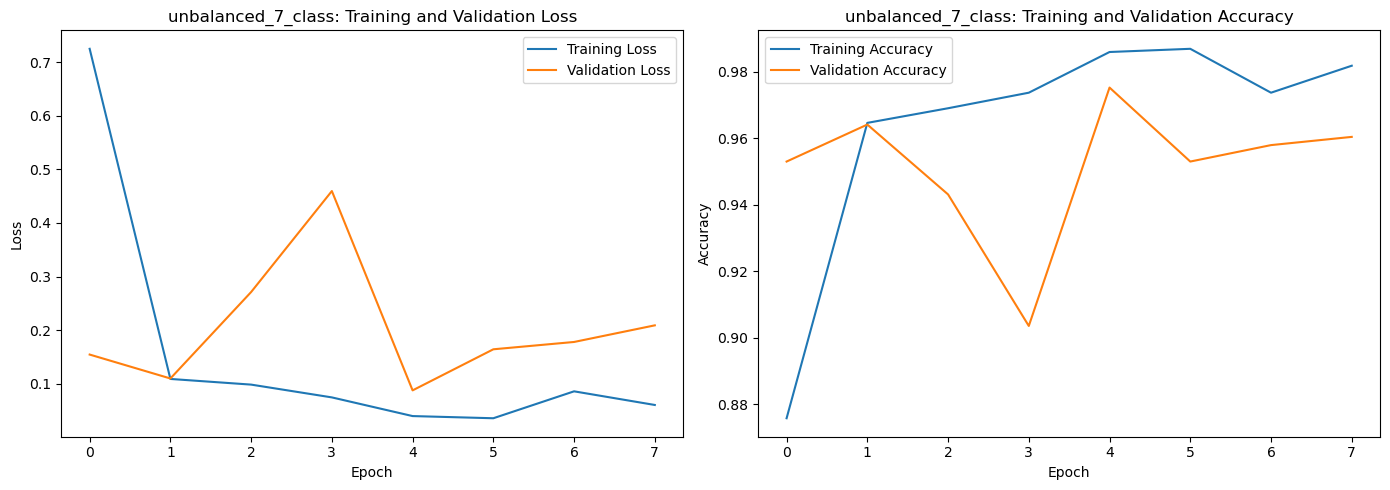

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step   
AUC for class 0: 1.00
AUC for class 1: 1.00
AUC for class 2: 1.00
AUC for class 3: 1.00
AUC for class 4: 1.00
AUC for class 5: 1.00
AUC for class 6: 1.00


In [11]:
unbal_metrics = NN_training(expression_train,label_train,expression_test,label_test,TFs,"unbalanced_7_class")


Using device: cuda
Epoch 1/100 - Train Loss: 0.4613 - Val Loss: 0.1757 - 
Epoch 2/100 - Train Loss: 0.1068 - Val Loss: 0.0769 - 
Epoch 3/100 - Train Loss: 0.0452 - Val Loss: 0.1731 - 
Epoch 4/100 - Train Loss: 0.0319 - Val Loss: 0.0803 - 
Epoch 5/100 - Train Loss: 0.0247 - Val Loss: 0.1045 - 
Early stopping triggered.


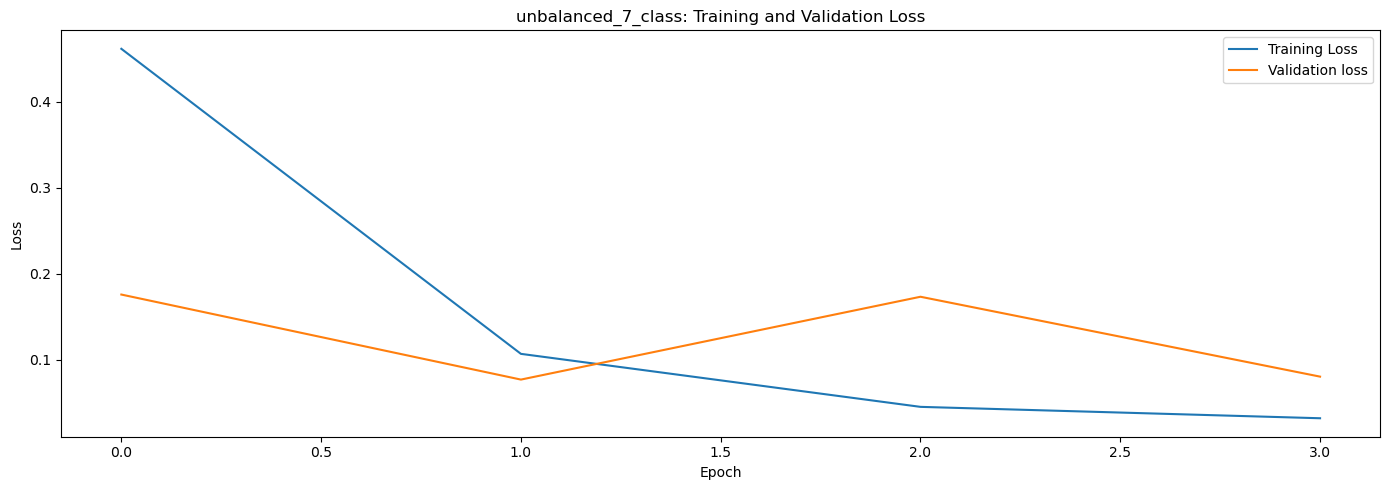

AUC for Kupffer: 0.98
AUC for Langerhans: 1.00
AUC for Macrophage: 1.00
AUC for Microglia: 1.00
AUC for Monocyte: 1.00
AUC for Osteoclast: 1.00
AUC for alveolar: 1.00


In [12]:
unbal_metrics_pytorch = pytorch_NN_training(expression_train,label_train,expression_test,label_test,TFs,"unbalanced_7_class")

In [13]:
unbal_metrics

{'f1_macro': 0.9424593008134364,
 'f1_weighted': 0.9630232755951611,
 'f1_micro': 0.9632516703786191,
 'roc_auc_micro': 0.9982624851949037,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.9964411338713014,
  np.str_('Langerhans'): 1.0,
  np.str_('Macrophage'): 0.9955285043345894,
  np.str_('Microglia'): 0.9998444746069449,
  np.str_('Monocyte'): 0.9967009064443562,
  np.str_('Osteoclast'): 0.9983397147019958,
  np.str_('alveolar'): 0.9958412098298677,
  'micro': 0.9982624851949037},
 'loss': 0.16256828606128693,
 'accuracy': 0.9632516503334045}

In [14]:
unbal_metrics_pytorch

{'f1_macro': 0.9401529058015815,
 'f1_weighted': 0.9710002635102353,
 'f1_micro': 0.9710467706013363,
 'roc_auc_micro': 0.9989172897804923,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.984936892199462,
  np.str_('Langerhans'): 1.0,
  np.str_('Macrophage'): 0.9950705066921606,
  np.str_('Microglia'): 0.99920352147193,
  np.str_('Monocyte'): 0.9964949715495568,
  np.str_('Osteoclast'): 0.9999661166265714,
  np.str_('alveolar'): 0.9998456849658577,
  'micro': 0.9989172897804923},
 'loss': 0.0010159389124858263,
 'accuracy': np.float64(0.9710467706013363)}

Epoch 1/100
505/520 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8708 - loss: 0.8522  

2026-10-27 14:32:59.627757: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-27 14:32:59.627815: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-27 14:32:59.867524: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_140', 4 bytes spill stores, 4 bytes spill loads

2026-10-27 14:33:01.084566: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Re

520/520 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8730 - loss: 0.8348

2026-10-27 14:33:08.022700: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-27 14:33:08.252951: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_28', 4 bytes spill stores, 4 bytes spill loads

2026-10-27 14:33:08.277770: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_28', 12 bytes spill stores, 12 bytes spill loads

2026-10-27 14:33:09.211156: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_37', 8 bytes spill

520/520 ━━━━━━━━━━━━━━━━━━━━ 16s 27ms/step - accuracy: 0.9498 - loss: 0.2448 - val_accuracy: 1.0000 - val_loss: 0.0047
Epoch 2/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9886 - loss: 0.0332 - val_accuracy: 1.0000 - val_loss: 0.0026
Epoch 3/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9949 - loss: 0.0150 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 4/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9882 - loss: 0.0468 - val_accuracy: 0.9706 - val_loss: 0.1398
Epoch 5/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9924 - loss: 0.0239 - val_accuracy: 1.0000 - val_loss: 4.9263e-05
Epoch 6/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9933 - loss: 0.0208 - val_accuracy: 0.9633 - val_loss: 0.1123
Epoch 7/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9976 - loss: 0.0070 - val_accuracy: 1.0000 - val_loss: 1.5403e-05
Epoch 8/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9956 - loss: 0.0166 - val_accura

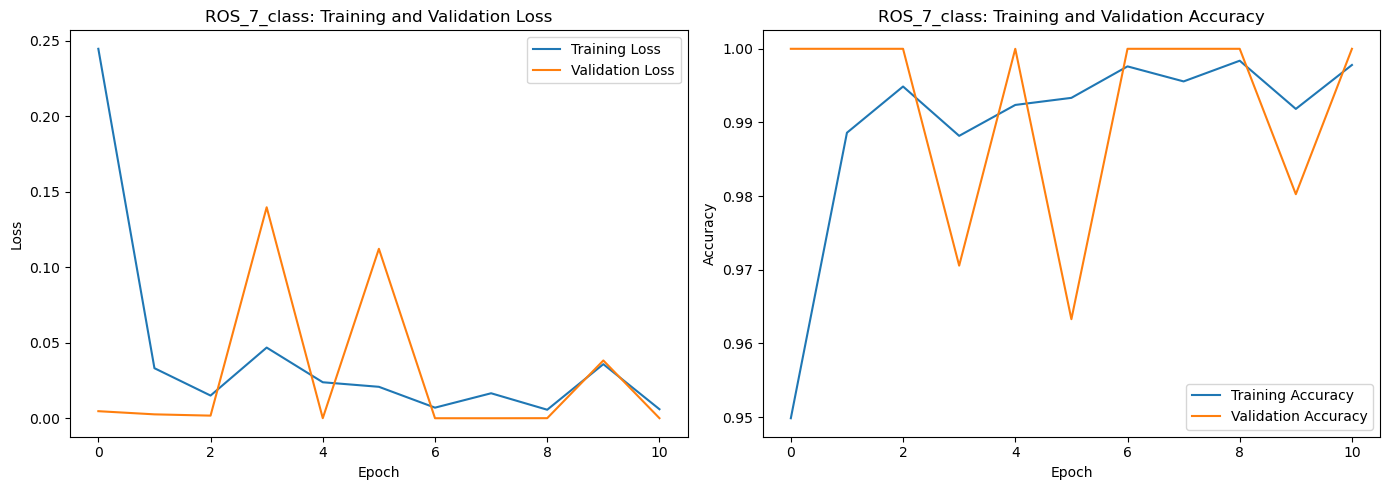

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step   
AUC for class 0: 0.93
AUC for class 1: 1.00
AUC for class 2: 1.00
AUC for class 3: 1.00
AUC for class 4: 1.00
AUC for class 5: 1.00
AUC for class 6: 1.00


In [15]:
ROS_metrics = NN_training(expression_ros,label_ros,expression_test,label_test,TFs,"ROS_7_class")


Using device: cuda
Epoch 1/100 - Train Loss: 0.1195 - Val Loss: 0.0353 - 
Epoch 2/100 - Train Loss: 0.0451 - Val Loss: 0.0376 - 
Epoch 3/100 - Train Loss: 0.0155 - Val Loss: 0.0401 - 
Epoch 4/100 - Train Loss: 0.0129 - Val Loss: 0.0224 - 
Epoch 5/100 - Train Loss: 0.0313 - Val Loss: 0.0225 - 
Epoch 6/100 - Train Loss: 0.0109 - Val Loss: 0.0251 - 
Epoch 7/100 - Train Loss: 0.0043 - Val Loss: 0.0197 - 
Epoch 8/100 - Train Loss: 0.0038 - Val Loss: 0.0213 - 
Epoch 9/100 - Train Loss: 0.0177 - Val Loss: 0.0519 - 
Epoch 10/100 - Train Loss: 0.0149 - Val Loss: 0.0404 - 
Early stopping triggered.


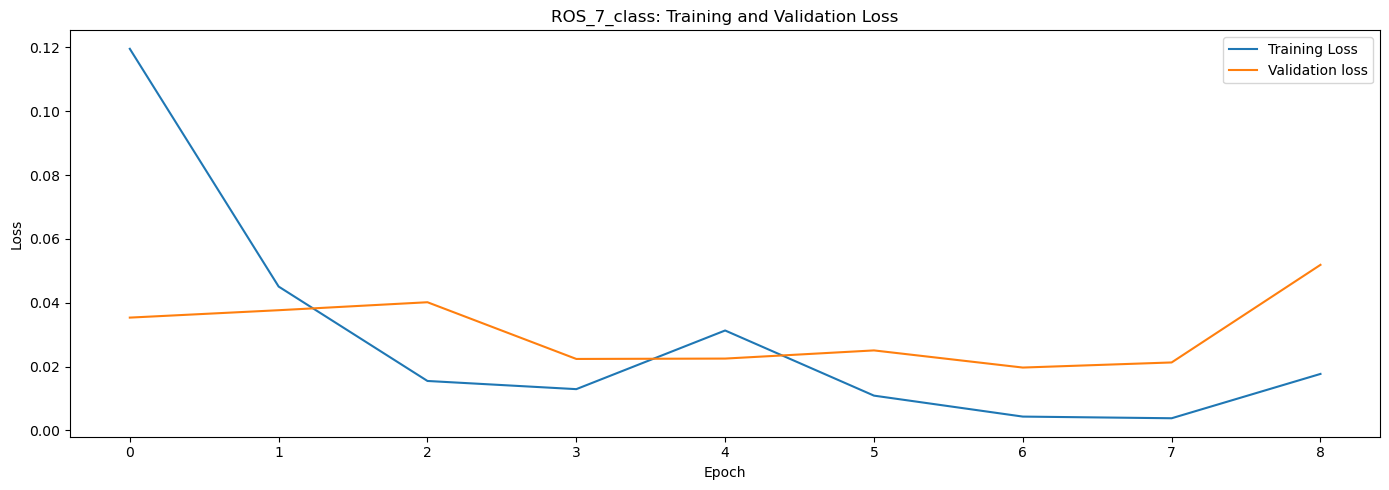

AUC for Kupffer: 0.93
AUC for Langerhans: 1.00
AUC for Macrophage: 1.00
AUC for Microglia: 1.00
AUC for Monocyte: 1.00
AUC for Osteoclast: 1.00
AUC for alveolar: 1.00


In [16]:
ROS_metrics_pytorch = pytorch_NN_training(expression_ros,label_ros,expression_test,label_test,TFs,"ROS_7_class")


In [17]:
ROS_metrics

{'f1_macro': 0.9672311076749637,
 'f1_weighted': 0.9791935901223888,
 'f1_micro': 0.9792130660727543,
 'roc_auc_micro': 0.9992935945901209,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.9300641423546452,
  np.str_('Langerhans'): 1.0,
  np.str_('Macrophage'): 0.9976592520744769,
  np.str_('Microglia'): 0.9997667119104173,
  np.str_('Monocyte'): 0.9978325834766882,
  np.str_('Osteoclast'): 1.0,
  np.str_('alveolar'): 0.9998919794761005,
  'micro': 0.9992935945901209},
 'loss': 0.11693230271339417,
 'accuracy': 0.9792130589485168}

In [18]:
ROS_metrics_pytorch

{'f1_macro': 0.9565205707072495,
 'f1_weighted': 0.9769291523007292,
 'f1_micro': 0.9769858945805494,
 'roc_auc_micro': 0.9986919179560214,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.9300641423546452,
  np.str_('Langerhans'): 0.9999999999999999,
  np.str_('Macrophage'): 0.9962974414784013,
  np.str_('Microglia'): 0.9997078007766843,
  np.str_('Monocyte'): 0.9973493118962552,
  np.str_('Osteoclast'): 0.9999661166265713,
  np.str_('alveolar'): 0.9996990856834227,
  'micro': 0.9986919179560214},
 'loss': 1.796958421833354e-05,
 'accuracy': np.float64(0.9769858945805494)}

Epoch 1/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9510 - loss: 0.2367 - val_accuracy: 1.0000 - val_loss: 0.0019
Epoch 2/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9868 - loss: 0.0414 - val_accuracy: 1.0000 - val_loss: 3.7257e-04
Epoch 3/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9922 - loss: 0.0246 - val_accuracy: 1.0000 - val_loss: 2.5852e-05
Epoch 4/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9949 - loss: 0.0169 - val_accuracy: 1.0000 - val_loss: 1.3153e-04
Epoch 5/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9868 - loss: 0.0548 - val_accuracy: 1.0000 - val_loss: 1.8516e-06
Epoch 6/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9968 - loss: 0.0098 - val_accuracy: 1.0000 - val_loss: 4.5447e-05
Epoch 7/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9973 - loss: 0.0084 - val_accuracy: 1.0000 - val_loss: 2.7707e-06
Epoch 8/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9977 -

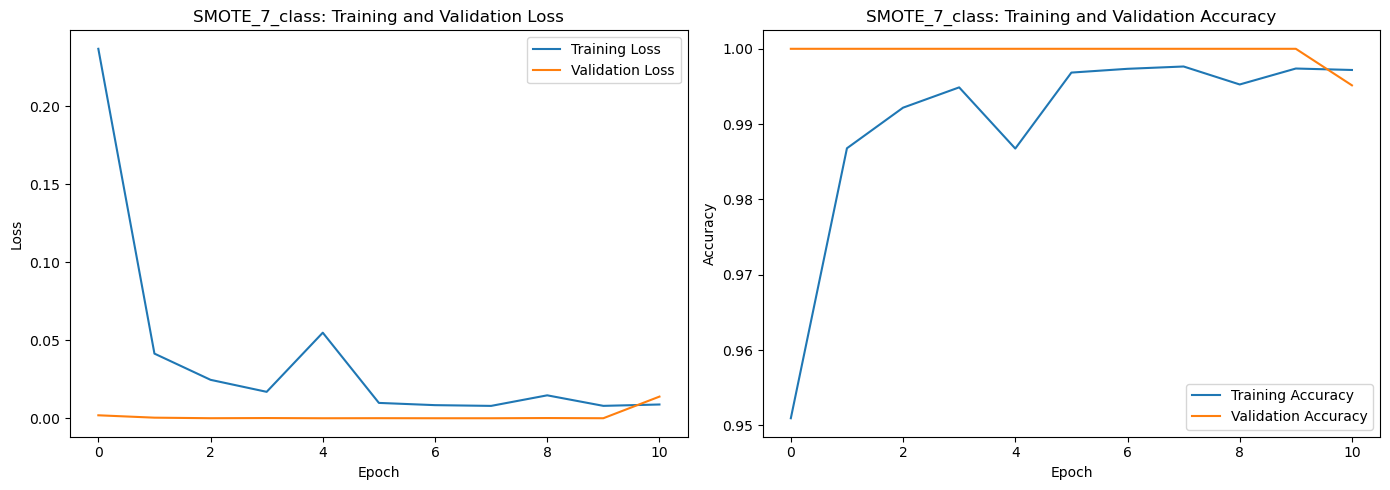

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step   
AUC for class 0: 0.96
AUC for class 1: 1.00
AUC for class 2: 1.00
AUC for class 3: 1.00
AUC for class 4: 1.00
AUC for class 5: 1.00
AUC for class 6: 1.00


In [19]:
SMOTE_metrics = NN_training(expression_SMOTE,label_SMOTE,expression_test,label_test,TFs,"SMOTE_7_class")

Using device: cuda
Epoch 1/100 - Train Loss: 0.1255 - Val Loss: 0.0280 - 
Epoch 2/100 - Train Loss: 0.0259 - Val Loss: 0.0292 - 
Epoch 3/100 - Train Loss: 0.0172 - Val Loss: 0.0253 - 
Epoch 4/100 - Train Loss: 0.0273 - Val Loss: 0.0360 - 
Epoch 5/100 - Train Loss: 0.0083 - Val Loss: 0.0320 - 
Epoch 6/100 - Train Loss: 0.0213 - Val Loss: 0.0275 - 
Early stopping triggered.


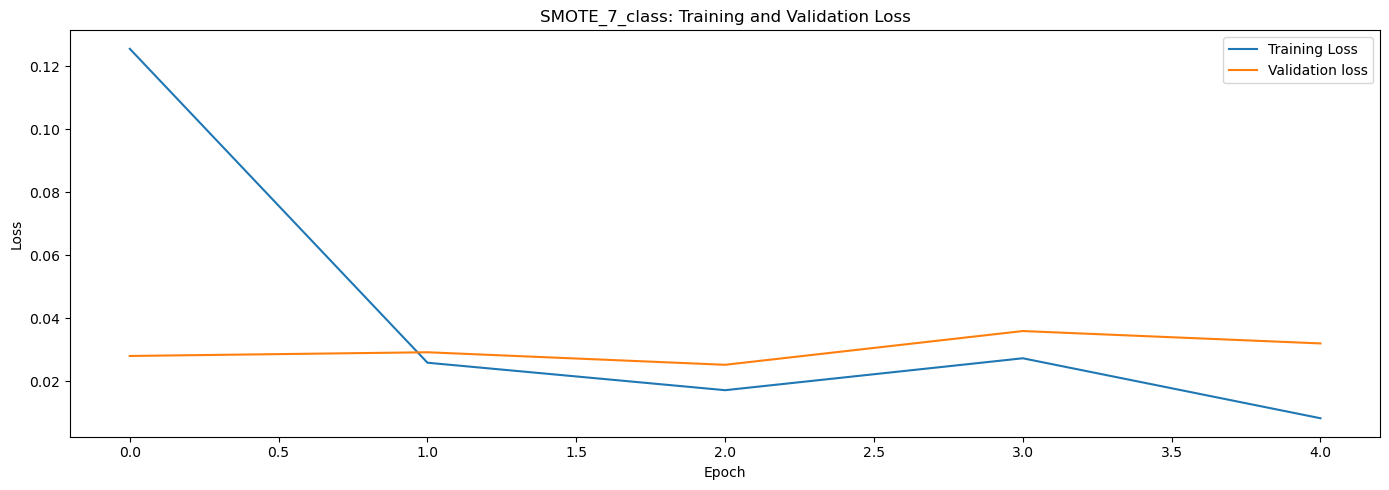

AUC for Kupffer: 0.96
AUC for Langerhans: 1.00
AUC for Macrophage: 1.00
AUC for Microglia: 1.00
AUC for Monocyte: 1.00
AUC for Osteoclast: 1.00
AUC for alveolar: 1.00


In [20]:
SMOTE_metrics_pytorch = pytorch_NN_training(expression_SMOTE,label_SMOTE,expression_test,label_test,TFs,"SMOTE_7_class")

In [21]:
SMOTE_metrics

{'f1_macro': 0.937729975459275,
 'f1_weighted': 0.9526985620228298,
 'f1_micro': 0.9524870081662955,
 'roc_auc_micro': 0.9974781274049384,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.9591144216842541,
  np.str_('Langerhans'): 0.9999898279913335,
  np.str_('Macrophage'): 0.9966025798696838,
  np.str_('Microglia'): 0.9996276816348074,
  np.str_('Monocyte'): 0.9962099157514004,
  np.str_('Osteoclast'): 1.0,
  np.str_('alveolar'): 0.999938273986343,
  'micro': 0.9974781274049384},
 'loss': 0.33119285106658936,
 'accuracy': 0.9524869918823242}

In [22]:
SMOTE_metrics_pytorch

{'f1_macro': 0.959729291932991,
 'f1_weighted': 0.9743867518973265,
 'f1_micro': 0.9743875278396437,
 'roc_auc_micro': 0.9992024147624193,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.9570866956341817,
  np.str_('Langerhans'): 1.0,
  np.str_('Macrophage'): 0.9968383949952663,
  np.str_('Microglia'): 0.9996771669871433,
  np.str_('Monocyte'): 0.9974786070310089,
  np.str_('Osteoclast'): 1.0,
  np.str_('alveolar'): 0.9998996952278076,
  'micro': 0.9992024147624193},
 'loss': 0.0002672320927348771,
 'accuracy': np.float64(0.9743875278396437)}

Epoch 1/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9512 - loss: 0.2411 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 2/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9900 - loss: 0.0300 - val_accuracy: 1.0000 - val_loss: 5.4951e-04
Epoch 3/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9891 - loss: 0.0356 - val_accuracy: 0.9979 - val_loss: 0.0044
Epoch 4/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9925 - loss: 0.0242 - val_accuracy: 1.0000 - val_loss: 6.2548e-07
Epoch 5/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9953 - loss: 0.0142 - val_accuracy: 1.0000 - val_loss: 1.5277e-04
Epoch 6/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9963 - loss: 0.0184 - val_accuracy: 1.0000 - val_loss: 1.9284e-05
Epoch 7/100
520/520 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9935 - loss: 0.0240 - val_accuracy: 1.0000 - val_loss: 9.9787e-05
85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9703 - loss: 0.1291   


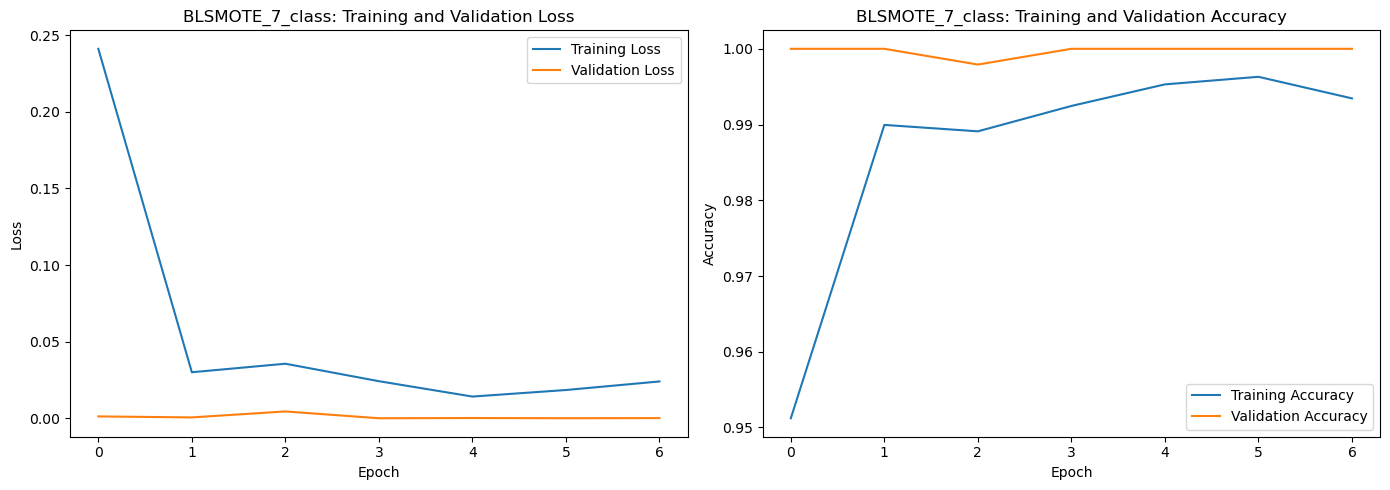

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step   
AUC for class 0: 0.99
AUC for class 1: 1.00
AUC for class 2: 1.00
AUC for class 3: 1.00
AUC for class 4: 1.00
AUC for class 5: 1.00
AUC for class 6: 1.00


In [23]:
BLSMOTE_metrics = NN_training(expression_BLSMOTE,label_BLSMOTE,expression_test,label_test,TFs,"BLSMOTE_7_class")

Using device: cuda
Epoch 1/100 - Train Loss: 0.1266 - Val Loss: 0.0489 - 
Epoch 2/100 - Train Loss: 0.0241 - Val Loss: 0.0285 - 
Epoch 3/100 - Train Loss: 0.0135 - Val Loss: 0.0706 - 
Epoch 4/100 - Train Loss: 0.0209 - Val Loss: 0.0187 - 
Epoch 5/100 - Train Loss: 0.0173 - Val Loss: 0.0197 - 
Epoch 6/100 - Train Loss: 0.0146 - Val Loss: 0.0133 - 
Epoch 7/100 - Train Loss: 0.0043 - Val Loss: 0.0140 - 
Epoch 8/100 - Train Loss: 0.0008 - Val Loss: 0.0202 - 
Epoch 9/100 - Train Loss: 0.0051 - Val Loss: 0.0270 - 
Early stopping triggered.


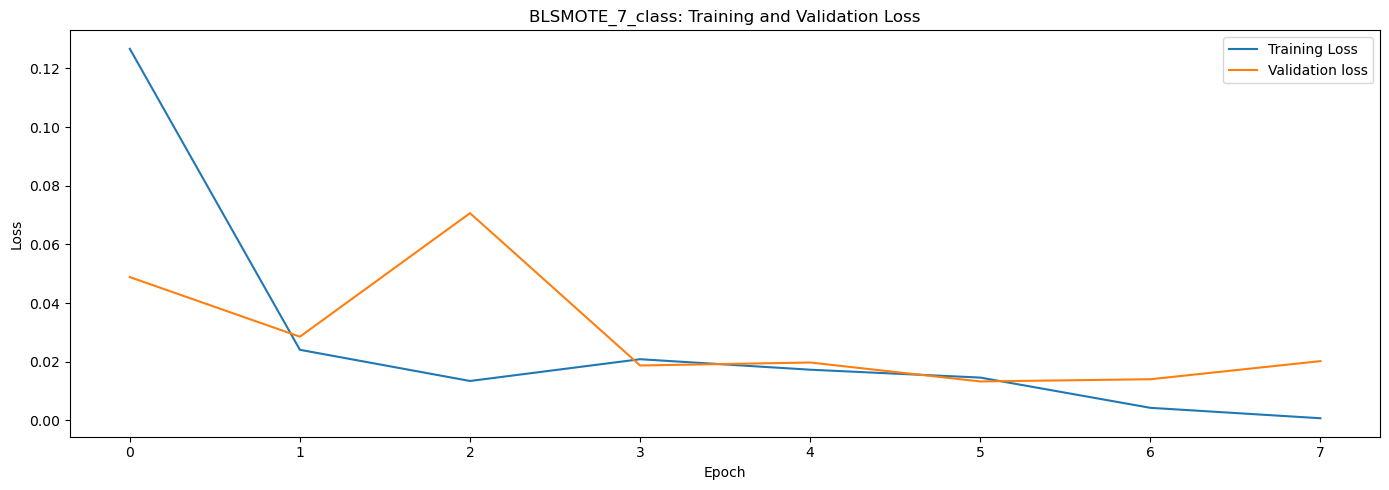

AUC for Kupffer: 0.87
AUC for Langerhans: 1.00
AUC for Macrophage: 1.00
AUC for Microglia: 1.00
AUC for Monocyte: 1.00
AUC for Osteoclast: 1.00
AUC for alveolar: 1.00


In [24]:
BLSMOTE_metrics_pytorch = pytorch_NN_training(expression_BLSMOTE,label_BLSMOTE,expression_test,label_test,TFs,"BLSMOTE_7_class")

In [25]:
BLSMOTE_metrics

{'f1_macro': 0.9418656230201524,
 'f1_weighted': 0.9702420647585266,
 'f1_micro': 0.9703043801039347,
 'roc_auc_micro': 0.9991681634809645,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.9932960893854749,
  np.str_('Langerhans'): 1.0,
  np.str_('Macrophage'): 0.996508891941562,
  np.str_('Microglia'): 0.9996064736266637,
  np.str_('Monocyte'): 0.9971833509770192,
  np.str_('Osteoclast'): 0.9999322332531427,
  np.str_('alveolar'): 0.9998148219590294,
  'micro': 0.9991681634809645},
 'loss': 0.12912121415138245,
 'accuracy': 0.9703043699264526}

In [26]:
BLSMOTE_metrics_pytorch

{'f1_macro': 0.9393175618419558,
 'f1_weighted': 0.9713117048845632,
 'f1_micro': 0.9714179658500371,
 'roc_auc_micro': 0.9987152726682169,
 'roc_auc_per_class': {np.str_('Kupffer'): 0.8746120422098076,
  np.str_('Langerhans'): 0.9999898279913333,
  np.str_('Macrophage'): 0.9969863233028272,
  np.str_('Microglia'): 0.9998515439429927,
  np.str_('Monocyte'): 0.9974664769970447,
  np.str_('Osteoclast'): 0.999898349879714,
  np.str_('alveolar'): 0.9997685274487866,
  'micro': 0.9987152726682169},
 'loss': 1.7327090563513918e-05,
 'accuracy': np.float64(0.9714179658500371)}

# Node Light up Test is below

In [3]:
# Import expression data and transcript data from filtered h5 file
filtered_file_tf = h5py.File("/scratch/by2372/pipeline/ARCHS4_Macrophages/Source_name_filtering/filtered_ARCHS4_TFs_7_class.h5", 'r')
ensembl_id = filtered_file_tf['ensembl_id'][...]
symbol = filtered_file_tf['symbol'][...]
expression = filtered_file_tf['data/filtered_expression'][...]
classes = filtered_file_tf['class_name'][...]
filtered_file_tf.close()

expression = np.log2(expression + 1)

# Read all names and decode bytes to strings
if isinstance(ensembl_id[0], bytes):
    ensembl_id = [s.decode('utf-8') for s in ensembl_id]

# Read all names and decode bytes to strings
if isinstance(symbol[0], bytes):
    symbol = [s.decode('utf-8') for s in symbol]

# Read all names and decode bytes to strings
if isinstance(classes[0], bytes):
    classes = [s.decode('utf-8') for s in classes]

# Make the transcript ID be the symbol _ ensembl ID
transcript_ID = []
for idx, sym in enumerate(symbol):
    ID = sym + "_" + ensembl_id[idx]
    transcript_ID.append(ID)

In [4]:
expression

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.02654945],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.06420036, 0.06644482, 0.        , ..., 0.        , 0.06980851,
        0.        ],
       [0.21878612, 0.24677539, 0.10608397, ..., 0.86243796, 0.21421312,
        0.67247695],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(13146, 10775), dtype=float32)

In [5]:
len(transcript_ID)

13146

In [6]:
len(classes)

10775

In [7]:
class_names = np.load('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/unbalanced_7_class_class_names.npy')
class_names

array(['Kupffer', 'Langerhans', 'Macrophage', 'Microglia', 'Monocyte',
       'Osteoclast', 'alveolar'], dtype='<U10')

In [8]:
test = np.where(class_names == "Macrophage")
test[0][0]

np.int64(2)

# Obtain Average Expression Values of Key TFs across all classes

In [33]:
def get_average_expression(express_mat,classes_list,TF_list):

    class_values = pd.Series(classes_list).value_counts(sort=False)
    class_dict = dict(zip(class_values.index,list(class_values)))

    TFs_interest = ["ZNF385A_ENST00000394313","ZNF385A_ENST00000546919",
                    "TSC22D1_ENST00000261489","CEBPB_ENST00000303004",
                    "CEBPA_ENST00000498907"]
    output_dict = dict()
    index_start = 0

    for key, value in class_dict.items():
        
        TF_interest_dict = dict()
        index_end = index_start + value
        
        for gene in TFs_interest:
            TF_index = TF_list.index(gene)
            row_avg = np.mean(express_mat[TF_index,index_start:index_end])
            TF_interest_dict[gene] = row_avg

        output_dict[key] = TF_interest_dict
        index_start = index_end

    return(output_dict)

In [34]:
Avg_express = get_average_expression(expression,classes,transcript_ID)

In [35]:
Avg_express

{'Kupffer': {'ZNF385A_ENST00000394313': np.float32(2.598419),
  'ZNF385A_ENST00000546919': np.float32(0.33050352),
  'TSC22D1_ENST00000261489': np.float32(4.226589),
  'CEBPB_ENST00000303004': np.float32(6.1426096),
  'CEBPA_ENST00000498907': np.float32(3.9177024)},
 'Langerhans': {'ZNF385A_ENST00000394313': np.float32(1.5686998),
  'ZNF385A_ENST00000546919': np.float32(0.29496467),
  'TSC22D1_ENST00000261489': np.float32(4.989775),
  'CEBPB_ENST00000303004': np.float32(3.9154167),
  'CEBPA_ENST00000498907': np.float32(2.1609395)},
 'Macrophage': {'ZNF385A_ENST00000394313': np.float32(5.122297),
  'ZNF385A_ENST00000546919': np.float32(1.261412),
  'TSC22D1_ENST00000261489': np.float32(4.2765956),
  'CEBPB_ENST00000303004': np.float32(7.048046),
  'CEBPA_ENST00000498907': np.float32(4.402033)},
 'Microglia': {'ZNF385A_ENST00000394313': np.float32(2.6834025),
  'ZNF385A_ENST00000546919': np.float32(1.772797),
  'TSC22D1_ENST00000261489': np.float32(2.4040165),
  'CEBPB_ENST00000303004': 

In [36]:
# Convert nested dict to DataFrame
# output_dict structure: {class: {gene: avg_tpm}}
df = pd.DataFrame(Avg_express).T # rows = classes, columns = genes
df.index.name = "Class"
df = df.reset_index()
df_melted = df.melt(id_vars="Class", var_name="TF", value_name="Average TPM")

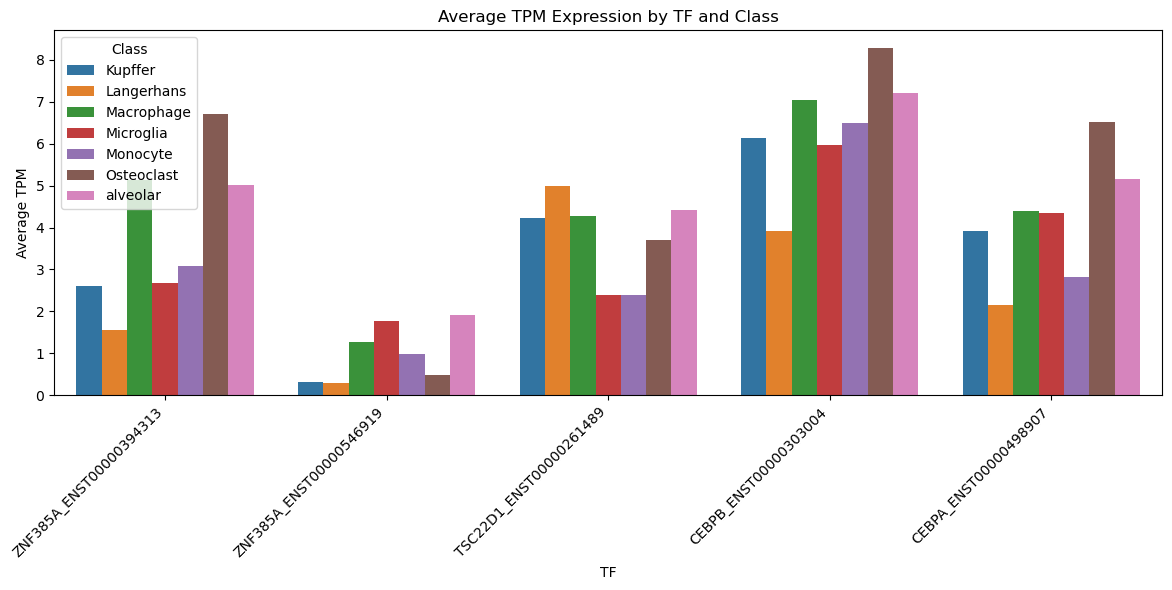

In [38]:
import seaborn as sns
# barplot
plt.figure(figsize=(12, 6))
sns.barplot(data=df_melted, x="TF", y="Average TPM", hue="Class")
plt.xticks(rotation=45, ha="right")
plt.title("Average TPM Expression by TF and Class")
plt.tight_layout()
plt.show()

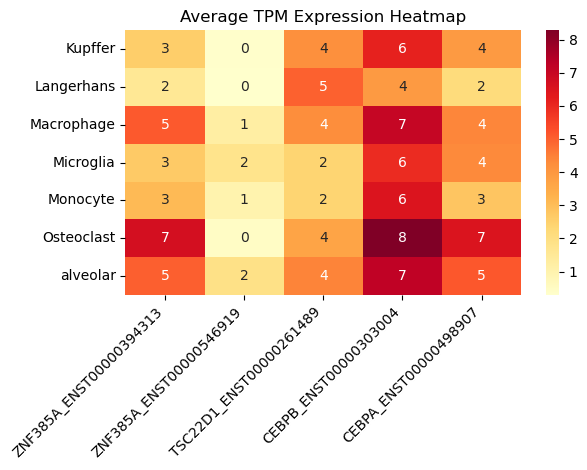

In [39]:
df_heat = pd.DataFrame(Avg_express).T  # rows = classes, columns = TFs
sns.heatmap(df_heat.astype(float), annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Average TPM Expression Heatmap")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [40]:
df_melted

,Class,TF,Average TPM
0,Kupffer,ZNF385A_ENST00000394313,2.598419
1,Langerhans,ZNF385A_ENST00000394313,1.568700
2,Macrophage,ZNF385A_ENST00000394313,5.122297
3,Microglia,ZNF385A_ENST00000394313,2.683403
4,Monocyte,ZNF385A_ENST00000394313,3.072562
5,Osteoclast,ZNF385A_ENST00000394313,6.707433
6,alveolar,ZNF385A_ENST00000394313,5.023851
7,Kupffer,ZNF385A_ENST00000546919,0.330504
8,Langerhans,ZNF385A_ENST00000546919,0.294965
9,Macrophage,ZNF385A_ENST00000546919,1.261412


### Implement the Node Light up technique as a function

In [9]:
def node_light_up(model_name,tf_names,express_mat,cell_type,NN_model,TFS): # NN_model = "keras" or "pytorch"

    # Has torch access GPU if one is available
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
    print(f"Using device: {device}") # Prints the device that was available/chosen

    # create square matrix of zeros. Number of rows and cols is number of TFs
    inp = np.zeros((len(TFS),len(TFS)))
    # Generate baseline TF expression values for the inp square matrix
    tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)
    for i in range(inp.shape[1]):
        inp[i, :] = tf_data.values
    # Generate doubled and halved expression for TFs. Only diagonals of the baseline square matrix is doubled or halved
    half = inp.copy()
    double = inp.copy()
    half[np.eye(half.shape[0]).astype(bool)] = 0.5*half[np.eye(half.shape[0]).astype(bool)]
    double[np.eye(double.shape[0]).astype(bool)] = 2*double[np.eye(double.shape[0]).astype(bool)]
    
    if (NN_model == "keras"):
        # load train keras model
        model = load_model('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + '_trained_NN.keras')
        # Import cell class names 
        class_names = np.load('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + '_class_names.npy')
        cell_type_index = np.where(class_names == cell_type)[0][0]

        background_pred = model.predict(inp)
        background_idx = np.argmax(background_pred, axis=1)
        background_labels = class_names[background_idx]
        
        double_pred = model.predict(double)
        double_idx = np.argmax(double_pred, axis=1)
        double_labels = class_names[double_idx]
        
        half_pred = model.predict(half)
        half_idx = np.argmax(half_pred, axis=1)
        half_labels = class_names[half_idx]
    
        double_background = double_pred[:,cell_type_index] - background_pred[:,cell_type_index]
        half_background = half_pred[:,cell_type_index] - background_pred[:,cell_type_index]
    
        score = (double_background - half_background) / 2
        score = pd.DataFrame(score, index=tf_names, columns=[cell_type])
        score_sorted = score.sort_values(by=cell_type, ascending=True)
            
    elif (NN_model == "pytorch"):
        class_names = np.load('/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + '_class_names_pytorch.npy')
        # Recreate the architecture
        model = NNClassifier(input_dim=len(TFS),num_classes=len(class_names))
        # Load the trained weights
        model.load_state_dict(
            torch.load(
                '/scratch/by2372/pipeline/ARCHS4_Macrophages/Trained_NN/' + model_name + "_trained_pytorch.pt",
                map_location=device,
                weights_only=True
            )
        )
        model = model.to(device)
        model.eval()

        cell_type_index = np.where(class_names == cell_type)[0][0]

        inp_tensor = torch.as_tensor(
            inp,
            dtype=torch.float32,
            device=device
        )
        half_tensor = torch.as_tensor(
            half,
            dtype=torch.float32,
            device=device
        )
        double_tensor = torch.as_tensor(
            double,
            dtype=torch.float32,
            device=device
        )
        
        with torch.no_grad():
            logits_background = model(inp_tensor)
            logits_half = model(half_tensor)
            logits_double = model(double_tensor)
            y_prob_background = torch.softmax(logits_background, dim=1).cpu().numpy()
            y_prob_half = torch.softmax(logits_half, dim=1).cpu().numpy()
            y_prob_double = torch.softmax(logits_double, dim=1).cpu().numpy()

        double_background = y_prob_double[:,cell_type_index] - y_prob_background[:,cell_type_index]
        half_background = y_prob_half[:,cell_type_index] - y_prob_background[:,cell_type_index]
    
        score = (double_background - half_background) / 2
        score = pd.DataFrame(score, index=tf_names, columns=[cell_type])
        score_sorted = score.sort_values(by=cell_type, ascending=True)

            
    else:
        raise ValueError("Please enter 'keras' or 'pytorch' for NN_model.")

    return score_sorted



In [12]:
unbalanced_macrophages = node_light_up("unbalanced_7_class",transcript_ID,expression,"Macrophage","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)
I0000 00:00:1793126332.160384 4069368 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 43516 MB memory:  -> device: 0, name: NVIDIA L40S, pci bus id: 0000:c2:00.0, compute capability: 8.9
2026-10-27 14:38:57.480351: I external/local_xla/xla/service/service.cc:163] XLA service 0x150868004eb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-27 14:38:57.480373: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA L40S, Compute Capability 8.9
2026-10-27 14:38:57.598830: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-27 14:38:57.864730: I external/lo

158/411 ━━━━━━━━━━━━━━━━━━━━ 0s 963us/step

I0000 00:00:1793126342.053375 4075452 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


377/411 ━━━━━━━━━━━━━━━━━━━━ 0s 938us/step

2026-10-27 14:39:02.483497: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-27 14:39:02.714931: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_9', 4 bytes spill stores, 4 bytes spill loads

2026-10-27 14:39:03.896611: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_18', 8 bytes spill stores, 8 bytes spill loads

2026-10-27 14:39:04.462980: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_18', 68 bytes spill s

411/411 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step 
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 998us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [13]:
unbalanced_macrophages.head(n=20)

,Macrophage
ATF4_ENST00000674920,-0.000418
FOS_ENST00000303562,-0.000344
KLF10_ENST00000285407,-0.000344
FOS_ENST00000556324,-0.000322
KLF2_ENST00000248071,-0.000313
VENTX_ENST00000325980,-0.000313
KLF6_ENST00000542957,-0.000300
PLSCR1_ENST00000494568,-0.000295
XBP1_ENST00000216037,-0.000282
DDIT3_ENST00000551116,-0.000267


In [46]:
for idx, t in enumerate(unbalanced_macrophages.index):
    if "ZNF385A" in str(t):
        print(idx)

12
133
183
339
350
475
1188
1852
7666
9611
10873
10954
11139
12963
13100


In [15]:
unbalanced_microglia = node_light_up("unbalanced_7_class",transcript_ID,expression,"Microglia","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 939us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 955us/step


In [16]:
unbalanced_microglia.head(n=20)

,Microglia
FOS_ENST00000303562,-1.814569e-07
KLF10_ENST00000285407,-1.561190e-07
YBX1_ENST00000436427,-1.430386e-07
PA2G4_ENST00000303305,-1.357720e-07
KLF6_ENST00000497571,-1.274385e-07
BATF_ENST00000286639,-1.202881e-07
ATF3_ENST00000341491,-1.091395e-07
FOS_ENST00000556324,-1.071046e-07
KLF2_ENST00000248071,-1.038297e-07
KLF6_ENST00000542957,-1.030283e-07


In [47]:
for idx, t in enumerate(unbalanced_microglia.index):
    if "ZNF385A" in str(t):
        print(idx)

198
250
860
1341
1438
1490
1665
4817
12163
12315
12691
12708
12871
13038
13077


In [18]:
unbalanced_monocyte = node_light_up("unbalanced_7_class",transcript_ID,expression,"Monocyte","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 953us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 977us/step


In [19]:
unbalanced_monocyte.head(n=20)

,Monocyte
BHLHE41_ENST00000242728,-0.000621
BHLHE41_ENST00000541271,-0.000564
TSC22D1_ENST00000261489,-0.000555
ETV5_ENST00000306376,-0.000529
ZNF706_ENST00000519744,-0.000435
JDP2_ENST00000419727,-0.000404
ETV5_ENST00000476890,-0.000390
NR1H3_ENST00000441012,-0.000386
MSANTD3_ENST00000374886,-0.000366
USF2_ENST00000599625,-0.000340


In [48]:
for idx, t in enumerate(unbalanced_monocyte.index):
    if "ZNF385A" in str(t):
        print(idx)

45
181
1978
2238
2308
3477
6029
11257
11978
12677
12791
12799
12975
13010
13133


In [21]:
unbalanced_alveolar = node_light_up("unbalanced_7_class",transcript_ID,expression,"alveolar","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 960us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 975us/step


In [22]:
unbalanced_alveolar.head(n=20)

,alveolar
KLF10_ENST00000285407,-0.000005
FOS_ENST00000303562,-0.000004
FOS_ENST00000554617,-0.000004
PA2G4_ENST00000303305,-0.000004
FOS_ENST00000556324,-0.000004
STAT6_ENST00000300134,-0.000004
ELF4_ENST00000308167,-0.000003
ZNF395_ENST00000344423,-0.000003
VENTX_ENST00000325980,-0.000003
ZEB2_ENST00000636026,-0.000003


In [49]:
for idx, t in enumerate(unbalanced_alveolar.index):
    if "ZNF385A" in str(t):
        print(idx)

24
100
221
391
701
743
845
2584
2676
3458
9444
11538
12172
12933
13087


In [24]:
unbalanced_Langerhans = node_light_up("unbalanced_7_class",transcript_ID,expression,"Langerhans","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 944us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 935us/step


In [25]:
unbalanced_Langerhans.head(n=20)

,Langerhans
FOS_ENST00000303562,-1.009053e-06
STAT6_ENST00000300134,-9.304781e-07
NME2_ENST00000512737,-8.713573e-07
CEBPB_ENST00000303004,-8.076709e-07
FOS_ENST00000554617,-7.863914e-07
FOS_ENST00000556324,-7.800213e-07
PA2G4_ENST00000303305,-7.641124e-07
KLF10_ENST00000285407,-7.572103e-07
MAFB_ENST00000373313,-7.514673e-07
FOSL2_ENST00000379619,-7.409290e-07


In [50]:
for idx, t in enumerate(unbalanced_Langerhans.index):
    if "ZNF385A" in str(t):
        print(idx)

24
124
255
372
699
887
1020
3471
5038
7169
9997
11964
12247
12849
13037


In [27]:
unbalanced_Kupffer = node_light_up("unbalanced_7_class",transcript_ID,expression,"Kupffer","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 950us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 964us/step


In [28]:
unbalanced_Kupffer.head(n=20)

,Kupffer
KLF10_ENST00000285407,-3.622512e-07
STAT6_ENST00000300134,-3.173483e-07
FOS_ENST00000303562,-3.019099e-07
ATF4_ENST00000674920,-2.704161e-07
FOS_ENST00000556324,-2.560407e-07
ZEB2_ENST00000636026,-1.994277e-07
FOS_ENST00000554617,-1.964110e-07
OLIG1_ENST00000498799,-1.947294e-07
PA2G4_ENST00000303305,-1.907684e-07
KLF2_ENST00000248071,-1.884416e-07


In [51]:
for idx, t in enumerate(unbalanced_Kupffer.index):
    if "ZNF385A" in str(t):
        print(idx)

51
239
244
340
600
873
2518
3934
9603
10264
11388
11907
12740
13038
13097


In [30]:
unbalanced_Osteoclast = node_light_up("unbalanced_7_class",transcript_ID,expression,"Osteoclast","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 956us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step


In [31]:
unbalanced_Osteoclast.head(n=20)

,Osteoclast
YBX1_ENST00000436427,-5.665754e-09
FOS_ENST00000303562,-5.510156e-09
KLF10_ENST00000285407,-5.426472e-09
CEBPZ_ENST00000234170,-5.350142e-09
ELF4_ENST00000308167,-5.314782e-09
FOS_ENST00000556324,-4.996359e-09
SPEN_ENST00000375759,-4.827129e-09
PA2G4_ENST00000303305,-4.700233e-09
XBP1_ENST00000216037,-4.685727e-09
FOSL2_ENST00000379619,-4.557613e-09


In [52]:
for idx, t in enumerate(unbalanced_Osteoclast.index):
    if "ZNF385A" in str(t):
        print(idx)

33
227
236
598
819
1385
2345
2578
4338
6867
9203
12402
12577
13003
13070


In [33]:
ROS_macrophages = node_light_up("ROS_7_class",transcript_ID,expression,"Macrophage","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 941us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 944us/step


In [34]:
ROS_macrophages.head(n=20) 

,Macrophage
KLF6_ENST00000542957,-0.054386
ATF4_ENST00000674920,-0.054020
OLIG1_ENST00000498799,-0.050391
ZNF511_ENST00000463816,-0.044526
DDIT3_ENST00000551116,-0.039222
KLF2_ENST00000248071,-0.038510
HES1_ENST00000476918,-0.036638
KLF10_ENST00000285407,-0.036598
CAMTA1_ENST00000461311,-0.036314
NFKB2_ENST00000651907,-0.035727


In [35]:
ROS_microglia = node_light_up("ROS_7_class",transcript_ID,expression,"Microglia","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 957us/step


In [36]:
ROS_microglia.head(n=20)

,Microglia
FOS_ENST00000303562,-1.655940e-09
BATF_ENST00000286639,-1.449146e-09
TSHZ3_ENST00000240587,-1.433636e-09
RELB_ENST00000589972,-1.360769e-09
ZNF395_ENST00000344423,-1.280923e-09
MXD1_ENST00000465446,-1.172900e-09
KLF6_ENST00000173785,-1.111415e-09
AHR_ENST00000242057,-1.074262e-09
ZEB2_ENST00000625161,-1.065032e-09
ZEB2_ENST00000629520,-1.033642e-09


In [37]:
SMOTE_macrophages = node_light_up("SMOTE_7_class",transcript_ID,expression,"Macrophage","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 998us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [38]:
SMOTE_macrophages.head(n=20)

,Macrophage
KLF6_ENST00000542957,-0.000233
PLSCR1_ENST00000494568,-0.000201
ATF4_ENST00000674920,-0.000201
KLF10_ENST00000285407,-0.000192
FOS_ENST00000556324,-0.000180
NFKB2_ENST00000651907,-0.000180
ZNF511_ENST00000463816,-0.000174
ZEB2_ENST00000629520,-0.000171
DDIT3_ENST00000551116,-0.000164
OLIG1_ENST00000498799,-0.000164


In [39]:
for idx, t in enumerate(SMOTE_macrophages.index):
    if "ZNF385A" in str(t):
        print(idx)

24
73
221
254
415
417
440
776
921
5822
9410
11603
12198
12676
13097


In [40]:
SMOTE_microglia = node_light_up("SMOTE_7_class",transcript_ID,expression,"Microglia","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 993us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 964us/step


In [41]:
SMOTE_microglia.head(n=20)

,Microglia
BATF_ENST00000286639,-5.435243e-08
RELB_ENST00000589972,-4.792575e-08
TSHZ3_ENST00000240587,-4.584862e-08
TSC22D1_ENST00000261489,-4.548899e-08
NR1H3_ENST00000441012,-4.428603e-08
ATF6B_ENST00000427136,-4.268286e-08
ZEB2_ENST00000444559,-3.892204e-08
MSC_ENST00000325509,-3.845146e-08
STAT5A_ENST00000590726,-3.781798e-08
BCL6_ENST00000438077,-3.621913e-08


In [42]:
BLSMOTE_macrophages = node_light_up("BLSMOTE_7_class",transcript_ID,expression,"Macrophage","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 985us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 992us/step


In [43]:
BLSMOTE_macrophages.head(n=20)

,Macrophage
KLF6_ENST00000542957,-0.035012
PLSCR1_ENST00000494568,-0.025315
OLIG1_ENST00000498799,-0.024931
ZNF511_ENST00000463816,-0.023426
FOS_ENST00000303562,-0.021884
KLF10_ENST00000285407,-0.021850
FOS_ENST00000556324,-0.021814
NFKB2_ENST00000651907,-0.021314
ZBTB7B_ENST00000535420,-0.020300
VENTX_ENST00000325980,-0.020246


In [44]:
BLSMOTE_microglia = node_light_up("BLSMOTE_7_class",transcript_ID,expression,"Microglia","keras",TFs)

Using device: cuda


/state/partition1/job-21125839/ipykernel_4069368/3633542740.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  tf_data = pd.DataFrame(express_mat).iloc[:,:].mean(1)


411/411 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 969us/step
411/411 ━━━━━━━━━━━━━━━━━━━━ 0s 952us/step


In [45]:
BLSMOTE_microglia.head(n=20)

,Microglia
BATF_ENST00000286639,-7.584232e-09
TSHZ3_ENST00000240587,-6.603525e-09
FOS_ENST00000303562,-6.459810e-09
MSC_ENST00000325509,-5.857522e-09
RELB_ENST00000589972,-5.414940e-09
ZEB2_ENST00000465070,-5.220770e-09
ATF6B_ENST00000427136,-4.679080e-09
YBX1_ENST00000321358,-4.493437e-09
TSC22D1_ENST00000261489,-4.367713e-09
PA2G4_ENST00000303305,-4.244583e-09
